# 2. Span, Independence, Basis and Dimension
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Spans in $\R^3$. Left, one vector spans a line. Middle, two vectors span a plane; the dots are the combinations $a_1v_1+a_2v_2$ with integer coefficients, a skewed lattice inside the plane. Right, a third vector $v_3$ lying in that plane adds nothing to the span, whereas $w$ sticks out of it and would enlarge the span to all of $\R^3$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


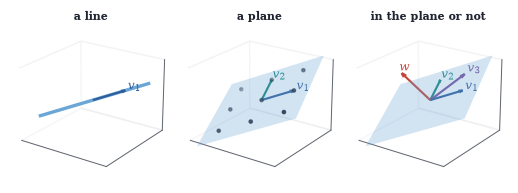

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

fig = plt.figure(figsize=(W, W * 0.36))
v1, v2 = np.array([1.0, 0.3, 0.6]), np.array([-0.3, 1.0, 0.4])
for k in range(3):
    ax = ax3d(fig, pos=131 + k, elev=22, azim=-55, lim=1.6)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    if k == 0:
        t = np.array([-1.7, 1.7]); ax.plot(*(np.outer(v1, t)), color=SKY, lw=2.2)
        arrow3d(ax, v1, color=BLUE, label="$v_1$")
    else:
        s, r = np.meshgrid([-1.5, 1.5], [-1.5, 1.5])
        P = s[..., None] * v1 + r[..., None] * v2
        ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color=SKY, alpha=0.3, lw=0, shade=False)
        arrow3d(ax, v1, color=BLUE, label="$v_1$"); arrow3d(ax, v2, color=TEAL, label="$v_2$")
        if k == 1:
            A, B = np.meshgrid(np.arange(-1, 2), np.arange(-1, 2))
            L = A.ravel()[:, None] * v1 + B.ravel()[:, None] * v2
            ax.scatter(*L.T, color=INK, s=4)
        else:
            arrow3d(ax, 0.8 * v1 + 0.9 * v2, color=PLUM, label="$v_3$")
            arrow3d(ax, np.cross(v1, v2) * 1.2, color=RED, label="$w$")
    ax.set_title(["a line", "a plane", "in the plane or not"][k], fontsize=7, pad=-4)

The exchange argument in $\R^3$, run by computer. Start from the spanning list $w_1,\dots,w_4$ (columns, top row). At each step an independent vector $u_k$ is inserted and the first vector that has become redundant (the first vector lying in the span of its predecessors) is removed; it is always a $w$. Blue tiles are $u$'s, grey tiles are $w$'s, and the rank of the list stays $3$ throughout.

(np.float64(-0.2), np.float64(6.2), np.float64(-3.4), np.float64(1.0))

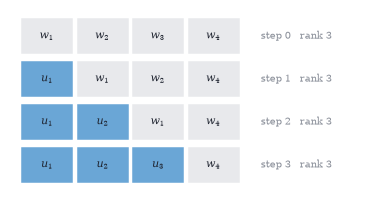

In [3]:
rng = np.random.default_rng(3)
Wl = [("w%d" % (j + 1), v) for j, v in enumerate(rng.integers(-2, 3, size=(4, 3)).astype(float))]
Ul = [("u%d" % (j + 1), v) for j, v in enumerate(np.eye(3) + rng.normal(scale=0.3, size=(3, 3)))]
rows = [list(Wl)]
cur = list(Wl)
for k, u in enumerate(Ul):
    cur.insert(k, u)
    for j in range(1, len(cur)):
        M = np.array([v for _, v in cur[:j]]).T
        if np.linalg.matrix_rank(np.column_stack([M, cur[j][1]])) == np.linalg.matrix_rank(M):
            cur.pop(j); break
    rows.append(list(cur))
fig, ax = plt.subplots(figsize=(W * 0.72, 1.8))
for i, r in enumerate(rows):
    for j, (name, v) in enumerate(r):
        col = SKY if name[0] == "u" else LIGHT
        ax.add_patch(plt.Rectangle((j, -i), 0.9, 0.8, color=col))
        ax.text(j + 0.45, -i + 0.4, f"${name[0]}_{name[1]}$", ha="center", va="center", fontsize=7)
    rk = np.linalg.matrix_rank(np.array([v for _, v in r]).T)
    ax.text(4.3, -i + 0.4, f"step {i}   rank {rk}", va="center", fontsize=6.5, color=GRAY)
ax.set_xlim(-0.2, 6.2); ax.set_ylim(-3.4, 1); ax.axis("off")

In [4]:
V = np.array([[2, 3, 1], [1, -1, 2], [7, 3, 8]], dtype=float).T   # columns are the vectors
print("rank:", np.linalg.matrix_rank(V))                          # 2 < 3: dependent
# Find the dependence: a vector a with V a = 0 (a basis of the null space, via SVD)
U, s, Vt = np.linalg.svd(V)
a = Vt[-1] / Vt[-1][-1] * -1
print("singular values:", s.round(4))
print("coefficients a:", a.round(6), "  V @ a =", (V @ a).round(12))

rank: 2
singular values: [11.5448  2.9527  0.    ]
coefficients a: [ 2.  3. -1.]   V @ a = [0. 0. 0.]


One vector, two coordinate systems. Left, $v=(2,1)$ in the standard basis. Right, the same vector in the basis $b_1=(1,1)$, $b_2=(-1,1)$, whose coordinate grid is rotated and stretched; the coordinates of $v$ are now $(\tfrac32,-\tfrac12)$, since $\tfrac32 b_1-\tfrac12 b_2=(2,1)$. The vector has not moved; only the language describing it has changed.

Text(0.5, 1.0, 'coordinates $(\\frac{3}{2},-\\frac{1}{2})$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


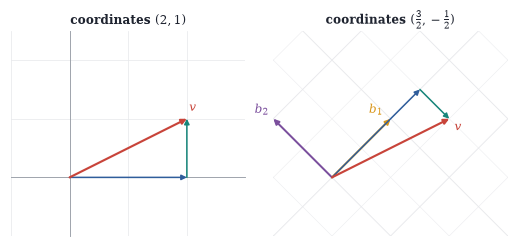

In [5]:
v = np.array([2.0, 1.0])
B = np.array([[1.0, -1.0], [1.0, 1.0]])
c = np.linalg.solve(B, v)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.3))
ax = plane(axs[0], (-1, 3, -1, 2.5), grid=True)
arrow(ax, (2, 0), color=BLUE, lw=1.0); arrow(ax, (0, 1), origin=(2, 0), color=TEAL, lw=1.0)
arrow(ax, v, color=RED, label="$v$", offset=(0.1, 0.18)); ax.set_title("coordinates $(2,1)$")
ax = axs[1]
ax.set_aspect("equal"); ax.axis("off")
t = np.linspace(-6, 6, 2)
for k in np.arange(-6, 6.5, 0.5):
    lw = 0.6 if k == int(k) else 0.3
    P = B @ np.vstack([t, k + 0 * t]); ax.plot(*P, color=LIGHT, lw=lw)
    P = B @ np.vstack([k + 0 * t, t]); ax.plot(*P, color=LIGHT, lw=lw)
arrow(ax, B[:, 0], color=GOLD, lw=1.3, label="$b_1$", offset=(-0.25, 0.15))
arrow(ax, B[:, 1], color=PLUM, lw=1.3, label="$b_2$", offset=(-0.2, 0.15))
arrow(ax, c[0] * B[:, 0], color=BLUE, lw=1.0)
arrow(ax, c[1] * B[:, 1], origin=c[0] * B[:, 0], color=TEAL, lw=1.0)
arrow(ax, v, color=RED, label="$v$", offset=(0.15, -0.15))
ax.set_xlim(-1, 3); ax.set_ylim(-1, 2.5); ax.set_title(r"coordinates $(\frac{3}{2},-\frac{1}{2})$")

Four bases of $\Poly_3(\R)$ on $[0,1]$. Monomials crowd together near $x=1$ and are hard to tell apart, the first sign of the ill-conditioning that makes them a poor numerical basis. Lagrange polynomials for equally spaced nodes equal $1$ at one node and $0$ at the others. Bernstein polynomials are nonnegative and sum to $1$. Shifted Legendre polynomials oscillate in a balanced way.

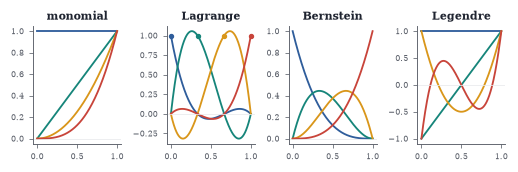

In [6]:
x = np.linspace(0, 1, 300)
nodes = np.linspace(0, 1, 4)
from math import comb
fig, axs = plt.subplots(1, 4, figsize=(W, 1.45), sharey=False)
cols = [BLUE, TEAL, GOLD, RED]
for k in range(4):
    axs[0].plot(x, x ** k, color=cols[k])
    lk = np.prod([(x - nodes[j]) / (nodes[k] - nodes[j]) for j in range(4) if j != k], axis=0)
    axs[1].plot(x, lk, color=cols[k]); axs[1].plot(nodes[k], 1, "o", color=cols[k], ms=2.5)
    axs[2].plot(x, comb(3, k) * x ** k * (1 - x) ** (3 - k), color=cols[k])
    axs[3].plot(x, np.polynomial.legendre.Legendre.basis(k)(2 * x - 1), color=cols[k])
for ax, t in zip(axs, ["monomial", "Lagrange", "Bernstein", "Legendre"]):
    ax.set_title(t, fontsize=7); ax.tick_params(labelsize=5); ax.axhline(0, color=LIGHT, lw=0.5)

Two planes through the origin in $\R^3$ (dimension $2$ each) meet in a line (dimension $1$), and together span $\R^3$: $3=2+2-1$. Two planes can never meet only at the origin in $\R^3$, since that would make their sum $4$-dimensional.

[]

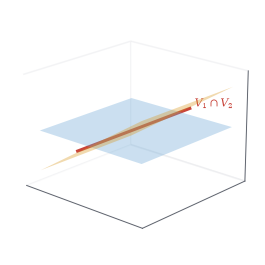

In [7]:
fig = plt.figure(figsize=(W * 0.58, W * 0.5))
ax = ax3d(fig, elev=20, azim=-48, lim=1.5)
plane3d(ax, (0, 0, 1), 0, lim=1.3, color=SKY, alpha=0.35)
plane3d(ax, (1, 0, -1.2), 0, lim=1.3, color=GOLD, alpha=0.35)
t = np.array([-1.6, 1.6]); ax.plot(0 * t, t, 0 * t, color=RED, lw=2)
ax.text(0, 1.75, 0, r"$V_1\cap V_2$", color=RED, fontsize=7)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

Effective dimension. Left, $200$ points that lie close to a plane in $\R^3$; exactly, they span all of $\R^3$, but one direction carries almost no variation. Right, the three singular values of the centred data matrix on a logarithmic scale: two are large and one is small, at the noise level. Numerical rank is the number of singular values above a chosen threshold.

Text(3.3, 1.15, 'threshold')

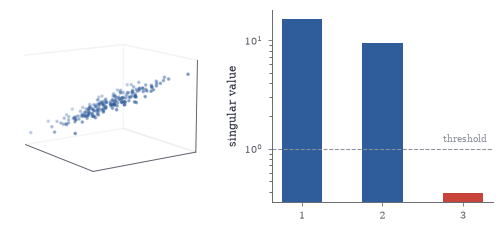

In [8]:
rng = np.random.default_rng(0)
basis = np.array([[1.0, 0.2, 0.5], [-0.3, 1.0, 0.4]])
coeff = rng.normal(size=(200, 2)) * [1.0, 0.6]
X = coeff @ basis + 0.03 * rng.normal(size=(200, 3))
s = np.linalg.svd(X - X.mean(0), compute_uv=False)
fig = plt.figure(figsize=(W, 2.0))
ax = ax3d(fig, pos=121, elev=12, azim=-35, lim=2)
ax.scatter(*X.T, s=2, color=BLUE, alpha=0.7); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
ax2 = fig.add_subplot(122)
ax2.bar([1, 2, 3], s, color=[BLUE, BLUE, RED], width=0.5); ax2.set_yscale("log")
ax2.set_xticks([1, 2, 3]); ax2.set_ylabel("singular value"); ax2.axhline(1.0, color=GRAY, ls="--", lw=0.7)
ax2.text(3.3, 1.15, "threshold", fontsize=6, color=GRAY, ha="right")

In [9]:
for c in [7.0, 8.0, 9.0]:
    M = np.array([[2, 3, 1], [1, -1, 2], [7, 3, c]], dtype=float)
    print(f"c = {c}:  rank = {np.linalg.matrix_rank(M)},  det = {np.linalg.det(M): .3f}")

c = 7.0:  rank = 3,  det =  5.000
c = 8.0:  rank = 2,  det =  0.000
c = 9.0:  rank = 3,  det = -5.000


In [10]:
# Verify parts (b): the five vectors form a basis iff the 5x5 matrix has rank 5.
Ub = np.array([[1, 6, 0, 0, 0], [0, 0, -2, 1, 0], [0, 0, -3, 0, 1]], dtype=complex)
E = np.eye(5)[[0, 2]]
print("rank of U-basis + e1, e3:", np.linalg.matrix_rank(np.vstack([Ub, E])))
print("U-basis satisfies the equations:", np.allclose(6 * Ub[:, 0], Ub[:, 1]),
      np.allclose(Ub[:, 2] + 2 * Ub[:, 3] + 3 * Ub[:, 4], 0))

rank of U-basis + e1, e3: 5
U-basis satisfies the equations: True True


Bernstein polynomials of degree $m=8$ (left) are nonnegative and sum to one, so $B_mf=\sum_k f(k/m)\,b_k$ is a weighted average of samples of $f$. Right, Bernstein approximations of $f(x)=\lvert x-0.4\rvert+0.3\sin 9x$ of increasing degree converge, slowly but surely.

Text(0.5, 1.0, 'approximation')

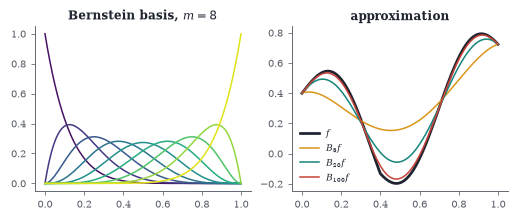

In [11]:
from math import comb
x = np.linspace(0, 1, 400)
m = 8
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
cm = plt.cm.viridis(np.linspace(0.05, 0.95, m + 1))
for k in range(m + 1):
    axs[0].plot(x, comb(m, k) * x ** k * (1 - x) ** (m - k), color=cm[k], lw=1)
axs[0].set_title("Bernstein basis, $m=8$")
f = lambda x: np.abs(x - 0.4) + 0.3 * np.sin(9 * x)
axs[1].plot(x, f(x), color=INK, lw=1.8, label="$f$")
for m, c in [(5, GOLD), (20, TEAL), (100, RED)]:
    B = sum(f(k / m) * comb(m, k) * x ** k * (1 - x) ** (m - k) for k in range(m + 1))
    axs[1].plot(x, B, color=c, lw=1, label=f"$B_{{{m}}}f$")
axs[1].legend(fontsize=6); axs[1].set_title("approximation")

A line $U$ in $\R^3$ ($m=1$, $n=3$) is the intersection of $n-m=2$ planes (hyperplanes of dimension $n-1=2$).

[]

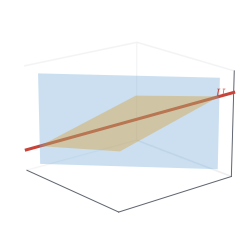

In [12]:
fig = plt.figure(figsize=(W * 0.55, W * 0.47))
ax = ax3d(fig, elev=18, azim=-40, lim=1.5)
u = np.array([1.0, 1.0, 0.6]); w1 = np.array([1.0, -1.0, 0.0]); w2 = np.array([0.0, 0.0, 1.0]) - 0.3 * u
for w, col in [(w2, SKY), (w1, GOLD)]:
    n = np.cross(u, w); plane3d(ax, n, 0, lim=1.3, color=col, alpha=0.35)
t = np.array([-1.5, 1.5]); ax.plot(*(np.outer(u, t)), color=RED, lw=2); ax.text(*(1.25 * u), "$U$", color=RED)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

Condition numbers of the monomial (Vandermonde) basis on equally spaced points in $[0,1]$ grow exponentially and reach $1/\varepsilon_{\text{mach}}\approx 10^{16}$ near $n=20$; the Chebyshev basis on Chebyshev points stays near $\sqrt{2}$.

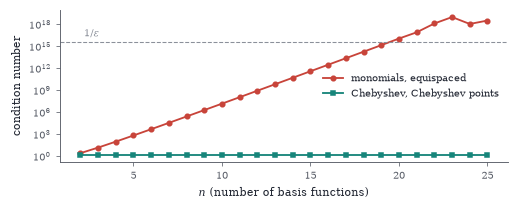

In [13]:
ns = np.arange(2, 26)
cv, cc = [], []
for n in ns:
    t = np.linspace(0, 1, n)
    cv.append(np.linalg.cond(np.vander(t, increasing=True)))
    tc = np.cos(np.pi * (np.arange(n) + 0.5) / n)
    cc.append(np.linalg.cond(np.polynomial.chebyshev.chebvander(tc, n - 1)))
fig, ax = plt.subplots(figsize=(W, 1.8))
ax.semilogy(ns, cv, "o-", color=RED, ms=3, label="monomials, equispaced")
ax.semilogy(ns, cc, "s-", color=TEAL, ms=3, label="Chebyshev, Chebyshev points")
ax.axhline(1 / np.finfo(float).eps, color=GRAY, ls="--", lw=0.7); ax.text(2.2, 2e16, "$1/\\varepsilon$", fontsize=6.5, color=GRAY)
ax.set_xlabel("$n$ (number of basis functions)"); ax.set_ylabel("condition number"); ax.legend()